# Módulo 1: Fundamentos, Espacios de Color y Mejoramiento Digital

**Objetivo.** Comprender la representación matricial de imágenes $F(x,y) = I$, evaluar la calidad espacial y cuántica, reducir ruido y mejorar el contraste tanto en el dominio espacial como frecuencial.

**Datos.** Se trabaja sobre un frame representativo de un registro del reflejo fotomotor. El video a utilizar se define en `config.py` mediante la variable `VIDEO_PATH`.

## 1.1 Carga, Muestreo y Espacios de Color

Frames totales: 909 | FPS: 29.5 | Duración: 30.8 s


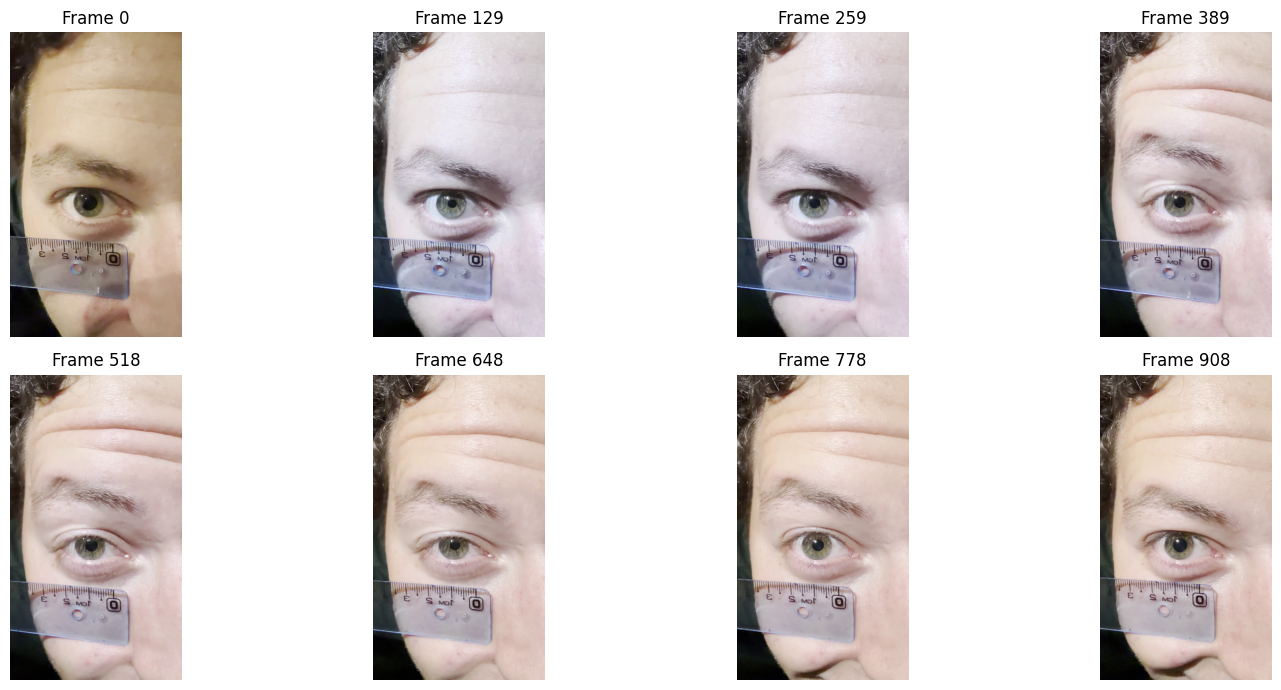

In [9]:
# Importación de librerías
import sys
sys.path.append("..")

import cv2
import matplotlib.pyplot as plt
from config import VIDEO_PATH

# Cargamos el video y obtenemos información básica
cap = cv2.VideoCapture(str(VIDEO_PATH))
n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fps = cap.get(cv2.CAP_PROP_FPS)
print(f"Frames totales: {n_frames} | FPS: {fps:.1f} | Duración: {n_frames/fps:.1f} s")

# Mostramos 8 frames repartidos a lo largo del video
indices = [int(i * (n_frames - 1) / 7) for i in range(8)]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, idx in zip(axes.flat, indices):
    cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ok, frame = cap.read()
    if ok:
        ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    ax.set_title(f"Frame {idx}")
    ax.axis("off")
plt.tight_layout()
plt.show()
cap.release()

### Selección del frame de trabajo y ROI

Se visualizaron varios frames distribuidos a lo largo del video y ahora se elige uno representativo: ojo abierto, en foco y con buen contraste entre pupila e iris.

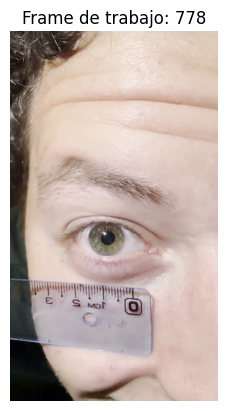

In [10]:
FRAME_IDX = 778

cap = cv2.VideoCapture(str(VIDEO_PATH))
cap.set(cv2.CAP_PROP_POS_FRAMES, FRAME_IDX)
ok, frame = cap.read()
cap.release()

plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.title(f"Frame de trabajo: {FRAME_IDX}")
plt.axis("off")
plt.show()

### Definición de la Región de Interés (ROI)

Se recorta una región centrada en el ojo para concentrar el análisis en la pupila y el iris, descartando párpados, piel y fondo.

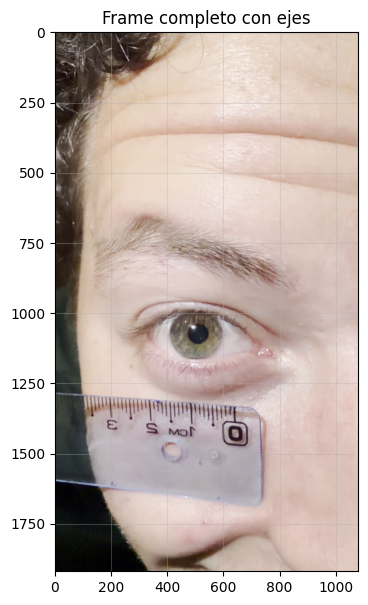

In [11]:
# Pasamos a RGB una sola vez y usamos esta versión de acá en adelante
frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 7))
plt.imshow(frame_rgb)
plt.title("Frame completo con ejes")
plt.grid(alpha=0.3)
plt.show()

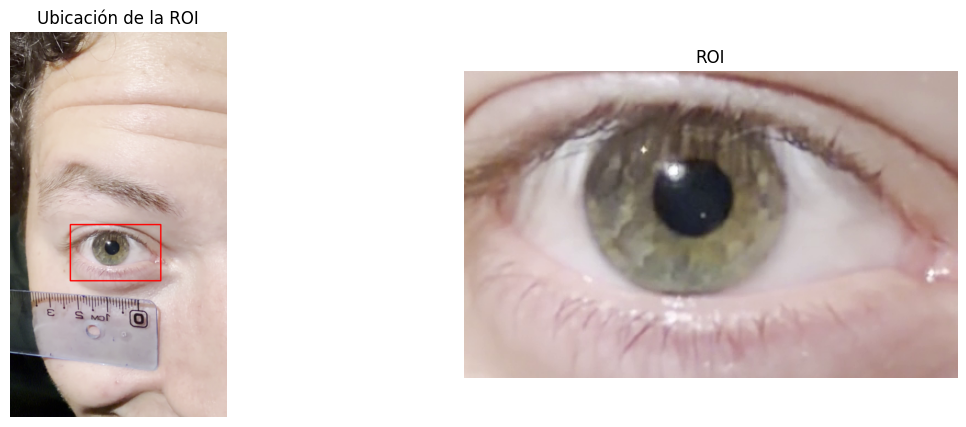

In [12]:
# ← Ajustar según tu imagen: esquina superior izquierda (x, y), ancho w y alto h
x, y, w, h = 300, 960, 450, 280

roi = frame_rgb[y:y+h, x:x+w]

# Dibujamos el rectángulo sobre una copia para verificar
vis = frame_rgb.copy()
cv2.rectangle(vis, (x, y), (x + w, y + h), (255, 0, 0), 5)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(vis)
axes[0].set_title("Ubicación de la ROI")
axes[1].imshow(roi)
axes[1].set_title("ROI")
for ax in axes:
    ax.axis("off")
plt.show()

### Dimensiones y profundidad de bits

In [13]:
def info_imagen(img, nombre):
    alto, ancho = img.shape[:2]
    canales = img.shape[2] if img.ndim == 3 else 1
    bits_canal = img.dtype.itemsize * 8
    print(f"--- {nombre} ---")
    print(f"Dimensiones (Ancho x Alto): {ancho} x {alto} px")
    print(f"Canales: {canales}")
    print(f"Tipo de dato: {img.dtype} → {bits_canal} bits por canal "
          f"({2**bits_canal} niveles), {bits_canal * canales} bits por píxel")
    print(f"Rango de valores: [{img.min()}, {img.max()}]\n")

info_imagen(frame_rgb, "Frame completo")
info_imagen(roi, "ROI")

--- Frame completo ---
Dimensiones (Ancho x Alto): 1080 x 1920 px
Canales: 3
Tipo de dato: uint8 → 8 bits por canal (256 niveles), 24 bits por píxel
Rango de valores: [0, 255]

--- ROI ---
Dimensiones (Ancho x Alto): 450 x 280 px
Canales: 3
Tipo de dato: uint8 → 8 bits por canal (256 niveles), 24 bits por píxel
Rango de valores: [16, 255]



### Resolución espacial: submuestreo

Se reduce la resolución de la ROI al 50%, 25% y 5% de la original, tomando 1 de cada *k* píxeles. 

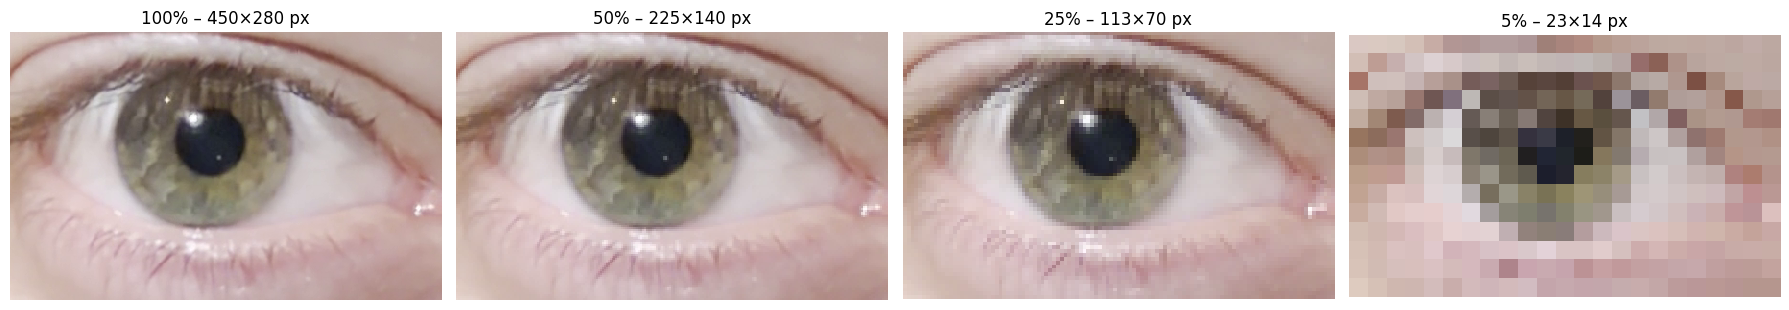

In [14]:
factores = [1, 2, 4, 20]   # 1 de cada k píxeles: 100%, 50%, 25%, 5%

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, k in zip(axes, factores):
    sub = roi[::k, ::k] #tomar una de cada k filas y una de cada k columnas
    ax.imshow(sub, interpolation="nearest")
    ax.set_title(f"{100 // k}% – {sub.shape[1]}×{sub.shape[0]} px")
    ax.axis("off")

plt.tight_layout()
plt.show()


Al 50% (225×140 px) la imagen es prácticamente indistinguible de la original: el borde de la pupila, la textura del iris, el reflejo corneal y las pestañas se siguen viendo con claridad.

Al 25% (113×70 px) se empieza a notar la pérdida de definición. La imagen se ve más borrosa, y se pierden los detalles más finos de la textura del iris. Sin embargo, la pupila, su borde y el reflejo siguen siendo identificables.

Al 5% (23×14 px) la imagen queda completamente pixelada. Solo se reconoce la forma general del ojo: la pupila aparece como un bloque oscuro de pocos píxeles, sin un borde definido, y desaparecen la textura del iris, las pestañas y el reflejo.

### Cuantización: profundidad de bits

Se reduce la cuantización de 8 bits (256 niveles) a 4 bits (16 niveles) y 2 bits (4 niveles) por canal, en la imagen color y en escala de grises.

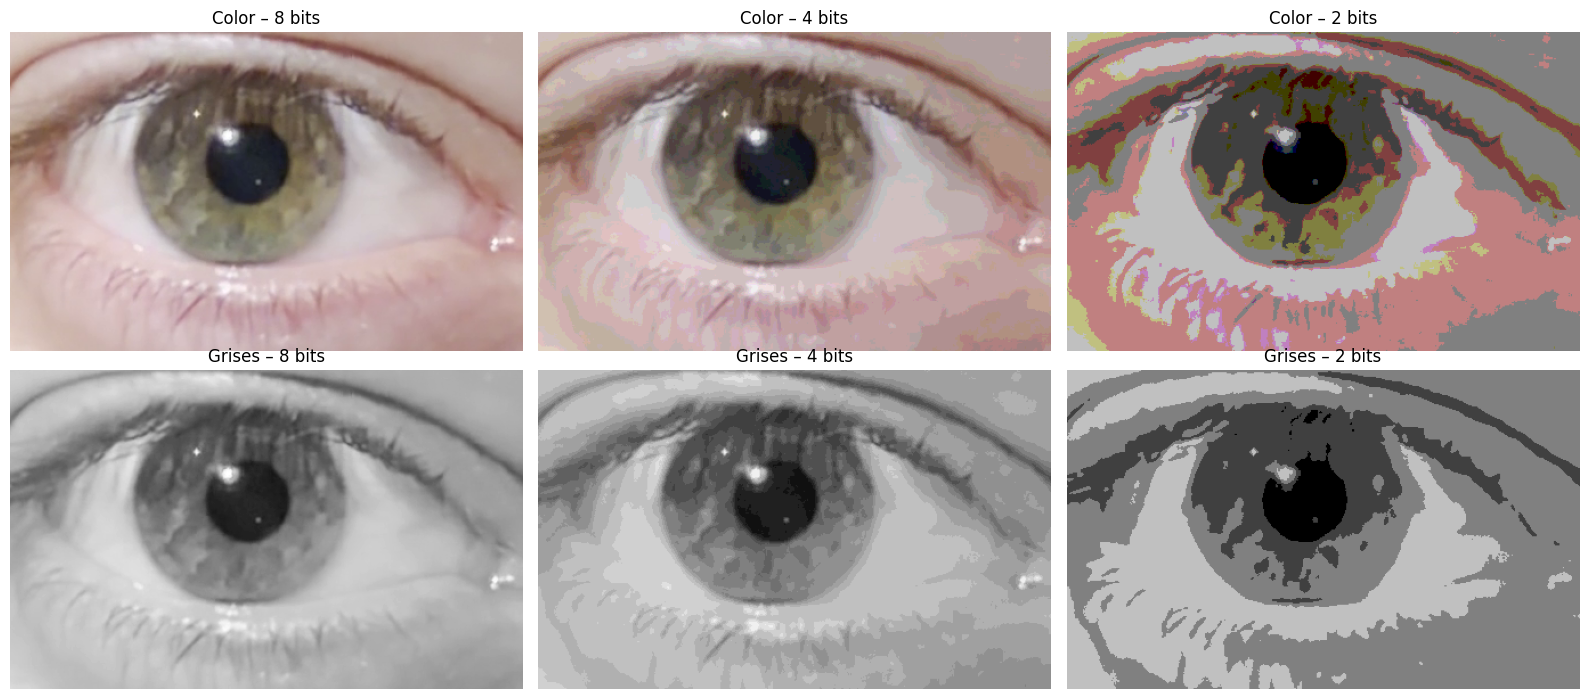

In [15]:
# Función que reduce la cantidad de niveles de intensidad de una imagen
def cuantizar(img, bits):
    niveles = 2 ** bits  #cantidad de niveles que queremos tener
    paso = 256 // niveles #tamaño de cada intervalo
    return (img // paso) * paso #dice en qué intervalo cae cada píxel. Todos los píxeles de un mismo intervalo quedan con el mismo valor

# Versión en escala de grises de la ROI
roi_gris = cv2.cvtColor(roi, cv2.COLOR_RGB2GRAY) #pasa de 3 canales (R, G, B) a 1 solo canal de intensidad

# Figura 
fig, axes = plt.subplots(2, 3, figsize=(16, 7))

# Recorremos las tres profundidades de bits
# j es el número de columna (0, 1, 2) y b es la cantidad de bits (8, 4, 2)
for j, b in enumerate([8, 4, 2]):
    axes[0, j].imshow(cuantizar(roi, b))
    axes[0, j].set_title(f"Color – {b} bits")
    axes[1, j].imshow(cuantizar(roi_gris, b), cmap="gray", vmin=0, vmax=255)
    axes[1, j].set_title(f"Grises – {b} bits")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Espacios de color

Se separa la ROI en sus tres canales R, G y B, y se visualiza cada uno en escala de grises. Luego se convierte la imagen de RGB a HSV y se grafican sus componentes H (matiz), S (saturación) y V (valor).

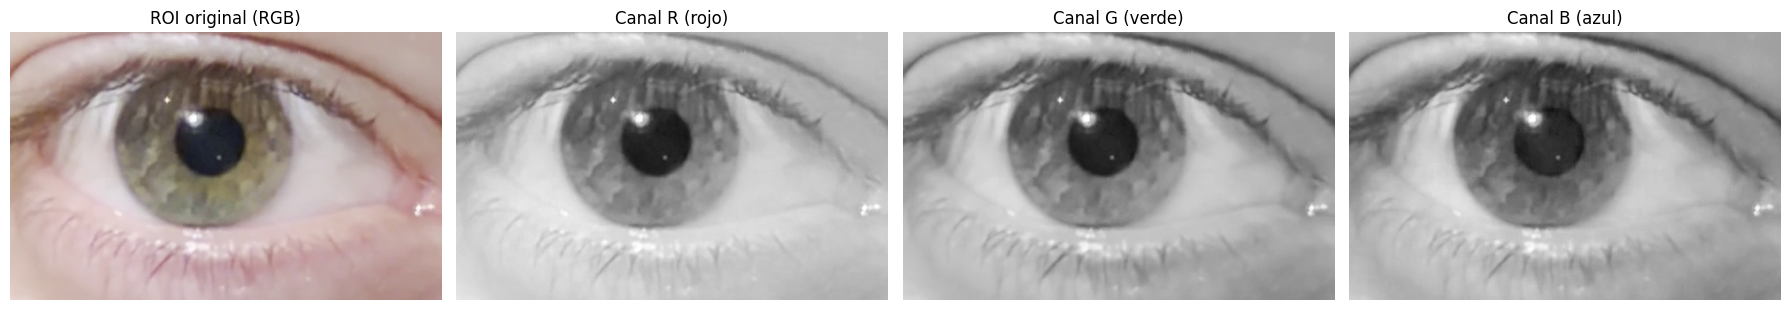

In [ ]:
# Separación de la ROI en sus tres canales R, G y B
R = roi[:, :, 0]   # todas las filas, todas las columnas, canal 0
G = roi[:, :, 1]
B = roi[:, :, 2]

# Cada canal es ahora una matriz de alto × ancho (2D)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

# Imagen original como referencia
axes[0].imshow(roi)
axes[0].set_title("ROI original (RGB)")

# Los tres canales, cada uno en escala de grises
for ax, canal, nombre in zip(axes[1:], [R, G, B], ["R (rojo)", "G (verde)", "B (azul)"]):
    ax.imshow(canal, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Canal {nombre}")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

Para leer las imágenes: en cada canal, blanco significa “mucho de ese color” y negro significa “nada de ese color”.

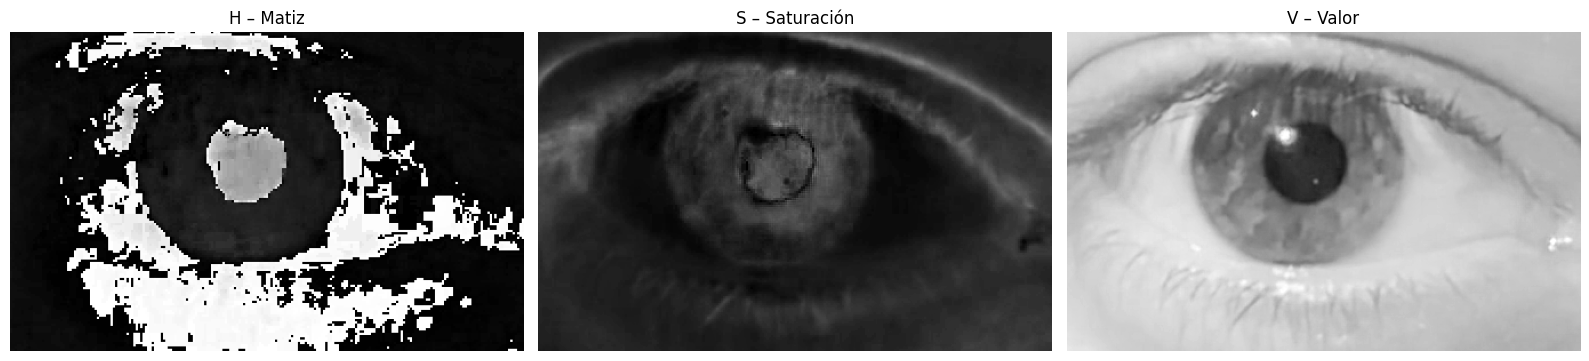

In [17]:
# Conversión de RGB a HSV

# HSV separa la información de color:
#   H (Hue / Matiz): qué color es (rojo, verde, azul...). Va de 0 a 179
#   S (Saturation): qué tan puro o intenso es el color. Va de 0 a 255
#   V (Value / Valor): qué tan claro u oscuro es. Va de 0 a 255

roi_hsv = cv2.cvtColor(roi, cv2.COLOR_RGB2HSV)

# Separamos los tres componentes, igual que con RGB
H = roi_hsv[:, :, 0]
S = roi_hsv[:, :, 1]
V = roi_hsv[:, :, 2]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].imshow(H, cmap="gray", vmin=0, vmax=179)
axes[0].set_title("H – Matiz")

axes[1].imshow(S, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("S – Saturación")

axes[2].imshow(V, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("V – Valor")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()